# Importing Libararies

In [1]:
import string
import pandas as pd
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Importing Dataset

In [2]:
formspring_dataset = pd.read_csv("Formspring.csv")

print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.head(10)

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,No
1,Q: <3<br>A: </3 ? haha jk! <33,No
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,No
3,Q: (:<br>A: ;(,No
4,Q: ******************MEOWWW*******************...,No
5,Q: any makeup tips? i suck at doing my makeup ...,No
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,No
7,Q: Are you a morning or night person?<br>A: Ni...,No
8,Q: are you a trusting person?<br>A: alreadi an...,No
9,Q: are you a trusting person?<br>A: Yes veryy ...,No


In [3]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.tail(10)

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
13137,Q: Your bio says &quot;Always ready for advent...,No
13138,Q: your going to mcdonalds what do you order ...,No
13139,Q: Your home alone. 2 robbers (of the opposite...,No
13140,Q: Your parents are divorced. One of them gets...,No
13141,Q: your thoughts on 2012? I think it&#039;ll b...,No
13142,Q: Youre at a party and your friend who drove ...,No
13143,Q: Youu2019re awesome :] Give yourself a compl...,No
13144,Q: Yu play with yurself ?<br>A: all the time. ...,No
13145,Q: yukk beer is disgusting. i can only drink i...,No
13146,Q: if i told u den it would make it all the le...,No


In [4]:
print(f"The 'Dataset - Formspring.csv' has {formspring_dataset.shape[0]:,} Rows and "\
      f"{formspring_dataset.shape[1]} Columns.")

The 'Dataset - Formspring.csv' has 13,147 Rows and 2 Columns.


In [5]:
formspring_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13147 entries, 0 to 13146
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    13147 non-null  object
 1   answer  13147 non-null  object
dtypes: object(2)
memory usage: 205.6+ KB


In [6]:
print("A generate descriptive statistics from the 'Dataset - Formspring.csv':")
print('-' * 73)
formspring_dataset.describe()

A generate descriptive statistics from the 'Dataset - Formspring.csv':
-------------------------------------------------------------------------


,text,answer
count,13147,13147
unique,13144,2
top,Q: Wait. Are you Cheyenne? I sent a request to...,No
freq,3,12295


In [7]:
print("Detecting missing values from the 'Dataset - Formspring.csv':")
print('-' * 63)
print(formspring_dataset.isnull().sum())

Detecting missing values from the 'Dataset - Formspring.csv':
---------------------------------------------------------------
text      0
answer    0
dtype: int64


In [8]:
print("A Value Count for the 'Element - answer', from the 'Dataset - Formspring.csv':")
print('-' * 83)
formspring_dataset["answer"].value_counts()

A Value Count for the 'Element - answer', from the 'Dataset - Formspring.csv':
-----------------------------------------------------------------------------------


answer
No     12295
Yes      852
Name: count, dtype: int64

In [9]:
formspring_text_features = formspring_dataset["text"].copy()
tfid_vectorizer = TfidfVectorizer(encoding="english")
formspring_features = tfid_vectorizer.fit_transform(formspring_text_features)

print("Text Features from the 'Dataset - Formspring.csv':")
print('-' * 63)
print(formspring_text_features)

Text Features from the 'Dataset - Formspring.csv':
---------------------------------------------------------------
0        Q: what&#039;s your favorite song? :D<br>A: I ...
1                           Q: <3<br>A: </3 ? haha jk! <33
2        Q: &quot;hey angel  you duh sexy&quot;<br>A: R...
3                                           Q: (:<br>A: ;(
4        Q: ******************MEOWWW*******************...
                               ...                        
13142    Q: Youre at a party and your friend who drove ...
13143    Q: Youu2019re awesome :] Give yourself a compl...
13144    Q: Yu play with yurself ?<br>A: all the time. ...
13145    Q: yukk beer is disgusting. i can only drink i...
13146    Q: if i told u den it would make it all the le...
Name: text, Length: 13147, dtype: object


In [10]:
print("Features from the 'Dataset - Formspring.csv':")
print('-' * 53)
print(formspring_features)

Features from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 254506 stored elements and shape (13147, 18775)>
  Coords	Values
  (0, 17947)	0.15984947496542218
  (0, 4)	0.21166783975854714
  (0, 18614)	0.16445580974678042
  (0, 6020)	0.5901629635353193
  (0, 15130)	0.3373860496444202
  (0, 2417)	0.06294444269439241
  (0, 9775)	0.19038717708585326
  (0, 16688)	0.26377533756496274
  (0, 10321)	0.30068023170403524
  (0, 15135)	0.43794630875263
  (0, 16619)	0.13666204960704684
  (0, 7574)	0.17265193864975523
  (1, 2417)	0.10517467075209345
  (1, 7324)	0.3741534117644445
  (1, 8965)	0.6831137869399059
  (1, 212)	0.6183066126040023
  (2, 2417)	0.05634780356239197
  (2, 7324)	0.20045437554062448
  (2, 13327)	0.5094343603709673
  (2, 7765)	0.2886547397744486
  (2, 1044)	0.4381590967996309
  (2, 18600)	0.0865259371250384
  (2, 5157)	0.42483910836891375
  (2, 14472)	0.3371973861965128
  (2, 13501)

In [11]:
saved_formspring_df = pd.DataFrame(formspring_text_features)

saved_formspring_df.to_csv("Formspring Text Features.csv")

<br>

__Label encoding:__ sklearn requires all inputs to be numeric, we need to convert all categorical variables (string labels) into numeric by encoding the categories. i.e., 'No', 'Yes' to 0, 1. sklearn provides LabelEncoder library for encoding labels between 0 to n-1 discrete classes, where n is the number of class-labels.

In [12]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
# Get specific column name:
column = ["answer"]
for i in column:
    # print(i)

    formspring_dataset[i] = label_encoder.fit_transform(formspring_dataset[i])

print("Formspring Dataset Data Types:")
print('-' * 33)
print(formspring_dataset.dtypes)

Formspring Dataset Data Types:
---------------------------------
text      object
answer     int64
dtype: object


In [13]:
print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.head(10)

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0
1,Q: <3<br>A: </3 ? haha jk! <33,0
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0
3,Q: (:<br>A: ;(,0
4,Q: ******************MEOWWW*******************...,0
5,Q: any makeup tips? i suck at doing my makeup ...,0
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0
7,Q: Are you a morning or night person?<br>A: Ni...,0
8,Q: are you a trusting person?<br>A: alreadi an...,0
9,Q: are you a trusting person?<br>A: Yes veryy ...,0


In [14]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.tail(10)

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
13137,Q: Your bio says &quot;Always ready for advent...,0
13138,Q: your going to mcdonalds what do you order ...,0
13139,Q: Your home alone. 2 robbers (of the opposite...,0
13140,Q: Your parents are divorced. One of them gets...,0
13141,Q: your thoughts on 2012? I think it&#039;ll b...,0
13142,Q: Youre at a party and your friend who drove ...,0
13143,Q: Youu2019re awesome :] Give yourself a compl...,0
13144,Q: Yu play with yurself ?<br>A: all the time. ...,0
13145,Q: yukk beer is disgusting. i can only drink i...,0
13146,Q: if i told u den it would make it all the le...,0


<br>

To ensure that you have a unique dataset, replace random_state = '0' with the 'last 4 digits of your student number'.

In [15]:
formspring_features_train, formspring_features_test, formspring_labels_train, \
formspring_labels_test = train_test_split(
    formspring_features, 
    formspring_dataset["answer"], 
    test_size=0.3, 
    random_state=4861
)

In [16]:
print("Features Train from the 'Dataset - Formspring.csv':")
print('-' * 53)

print(formspring_features_train)

Features Train from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 178429 stored elements and shape (9202, 18775)>
  Coords	Values
  (0, 2417)	0.03554805974627196
  (0, 16619)	0.07718029577394415
  (0, 18600)	0.054586496510325856
  (0, 9954)	0.10429408251589235
  (0, 10481)	0.10405181432957193
  (0, 9348)	0.12154826875015336
  (0, 4873)	0.08636409381158049
  (0, 12620)	0.4254544835107159
  (0, 8361)	0.11959751173117253
  (0, 2859)	0.12741497551261466
  (0, 8079)	0.11654039500223604
  (0, 2720)	0.10971778532157818
  (0, 15542)	0.16819394890336758
  (0, 16149)	0.26280618295286606
  (0, 13058)	0.26801765201244987
  (0, 12703)	0.6468133399762015
  (0, 1905)	0.34804670737560567
  (1, 2417)	0.04981611402851899
  (1, 18600)	0.076496077535172
  (1, 7044)	0.23073939557861475
  (1, 14338)	0.23073939557861475
  (1, 15567)	0.2641370614165871
  (1, 17611)	0.4186836846730796
  (1, 12013)	0.2850403818

In [17]:
print("Features Test from the 'Dataset - Formspring.csv':")
print('-' * 53)
print(formspring_features_test)

Features Test from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 76077 stored elements and shape (3945, 18775)>
  Coords	Values
  (0, 2417)	0.08712880687700382
  (0, 11539)	0.43485669417616285
  (0, 757)	0.5432942623741092
  (0, 17272)	0.7128390919511512
  (1, 17947)	0.07632386129324026
  (1, 2417)	0.030054292730247182
  (1, 16619)	0.06525248406674124
  (1, 18600)	0.04615043850352479
  (1, 1149)	0.1336978286401416
  (1, 1030)	0.07126466246482527
  (1, 11716)	0.16632759683822804
  (1, 18021)	0.10472726260005896
  (1, 10053)	0.10950216655509368
  (1, 8720)	0.08034314350188486
  (1, 8434)	0.08303028290530445
  (1, 18166)	0.09985247028149877
  (1, 18621)	0.16109284100498447
  (1, 16341)	0.262822663092301
  (1, 18273)	0.16274762366610537
  (1, 16329)	0.08283111522658114
  (1, 876)	0.22116415535751946
  (1, 12344)	0.1191615934378546
  (1, 15258)	0.1952038601494836
  (1, 3903)	0.1329171537679

In [18]:
print("First 10 Elements from Formspring Labels Train:")
print('-' * 53)
formspring_labels_train.head(10)

First 10 Elements from Formspring Labels Train:
-----------------------------------------------------


5634     0
3350     0
8939     0
5109     0
1001     0
5754     0
12939    0
7619     0
5705     0
10248    0
Name: answer, dtype: int64

In [19]:
print("Last 10 Elements from Formspring Labels Train:")
print('-' * 53)
formspring_labels_train.tail(10)

Last 10 Elements from Formspring Labels Train:
-----------------------------------------------------


3054     0
4392     0
10829    0
9085     0
2704     1
4125     0
9563     0
9813     0
12745    0
2101     0
Name: answer, dtype: int64

In [20]:
print("First 10 Elements from Formspring Labels Test:")
print('-' * 53)
formspring_labels_test.head(10)

First 10 Elements from Formspring Labels Test:
-----------------------------------------------------


623      0
9971     0
10347    0
8597     0
3371     0
11076    0
10181    0
13026    0
1163     0
3325     0
Name: answer, dtype: int64

In [21]:
print("Last 10 Elements from Formspring Labels Test:")
print('-' * 53)
formspring_labels_test.tail(10)

Last 10 Elements from Formspring Labels Test:
-----------------------------------------------------


6376     0
5645     0
54       0
9025     0
11808    0
7440     0
9434     0
2928     0
7176     0
7887     0
Name: answer, dtype: int64

In [22]:
from sklearn.model_selection import GridSearchCV

from sklearn.svm import (SVR, SVC)
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import (Ridge, RidgeClassifier, SGDRegressor, SGDClassifier, LogisticRegression)
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report
)   

from matplotlib import style
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [23]:
# ----------------------------- Metric Scores: C-Support Vector Classification ----------------------------- #
svc = SVC(kernel="sigmoid", gamma=1.0)

svc.fit(formspring_features_train, formspring_labels_train)

svc_prediction = svc.predict(formspring_features_test)
svc_accuracy_score = accuracy_score(formspring_labels_test, svc_prediction)
svc_precision_score = precision_score(formspring_labels_test, svc_prediction)
svc_recall_score = recall_score(formspring_labels_test, svc_prediction)
svc_f1_score = f1_score(formspring_labels_test, svc_prediction)
# ---------------------------------------------------------------------------------------------------------- #
# -------------------------------------- Metric Scores: MultinomialNB -------------------------------------- #
mnb = MultinomialNB(alpha=0.2)

mnb.fit(formspring_features_train, formspring_labels_train)

mnb_prediction = mnb.predict(formspring_features_test)
mnb_accuracy_score = accuracy_score(formspring_labels_test, mnb_prediction)
mnb_precision_score = precision_score(formspring_labels_test, mnb_prediction)
mnb_recall_score = recall_score(formspring_labels_test, mnb_prediction)
mnb_f1_score = f1_score(formspring_labels_test, mnb_prediction)
# ---------------------------------------------------------------------------------------------------------- #
# --------------------------------- Metric Scores: DecisionTreeClassifier ---------------------------------- #
dtc = DecisionTreeClassifier()

dtc.fit(formspring_features_train, formspring_labels_train)

dtc_prediction = dtc.predict(formspring_features_test)
dtc_accuracy_score = accuracy_score(formspring_labels_test, dtc_prediction)
dtc_precision_score = precision_score(formspring_labels_test, dtc_prediction)
dtc_recall_score = recall_score(formspring_labels_test, dtc_prediction)
dtc_f1_score = f1_score(formspring_labels_test, dtc_prediction)
# ---------------------------------------------------------------------------------------------------------- #
print(f"""________Evaluation for: C-Support Vector Classification________
Model Type:         {svc}
Accuracy Score:     {svc_accuracy_score:%}
Precision Score:    {svc_precision_score:%}
Recall Score:       {svc_recall_score:%}
F1-Score:           {svc_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, svc_prediction)}

C-Support Vector Classification - Classification Report:
{classification_report(formspring_labels_test, svc_prediction)}
----------------------------THE END----------------------------
______Evaluation for: Multinomial Naive Bayes Classifier_______
Model Type:         {mnb}
Accuracy Score:     {mnb_accuracy_score:%}
Precision Score:    {mnb_precision_score:%}
Recall Score:       {mnb_recall_score:%}
F1-Score:           {mnb_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, mnb_prediction)}

C-Support Vector Classification - Classification Report:
{classification_report(formspring_labels_test, mnb_prediction)}
----------------------------THE END----------------------------
___________Evaluation for: Decision Tree Classifier____________
Model Type:         {dtc}
Accuracy Score:     {dtc_accuracy_score:%}
Precision Score:    {dtc_precision_score:%}
Recall Score:       {dtc_recall_score:%}
F1-Score:           {dtc_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, dtc_prediction)}

C-Support Vector Classification - Classification Report:
{classification_report(formspring_labels_test, dtc_prediction)}
----------------------------THE END----------------------------""")
# ---------------------------------------------------------------------------------------------------------- #

________Evaluation for: C-Support Vector Classification________
Model Type:         SVC(gamma=1.0, kernel='sigmoid')
Accuracy Score:     95.082383%
Precision Score:    80.519481%
Recall Score:       25.726141%
F1-Score:           38.993711%

C-Support Vector Classification - Confusion Matrix:
[[3689   15]
 [ 179   62]]

C-Support Vector Classification - Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      3704
           1       0.81      0.26      0.39       241

    accuracy                           0.95      3945
   macro avg       0.88      0.63      0.68      3945
weighted avg       0.94      0.95      0.94      3945

----------------------------THE END----------------------------
______Evaluation for: Multinomial Naive Bayes Classifier_______
Model Type:         MultinomialNB(alpha=0.2)
Accuracy Score:     94.017744%
Precision Score:    53.623188%
Recall Score:       15.352697%
F1-Score:           23.87096

findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.
findfont: Font family 'Arial Black' not found.


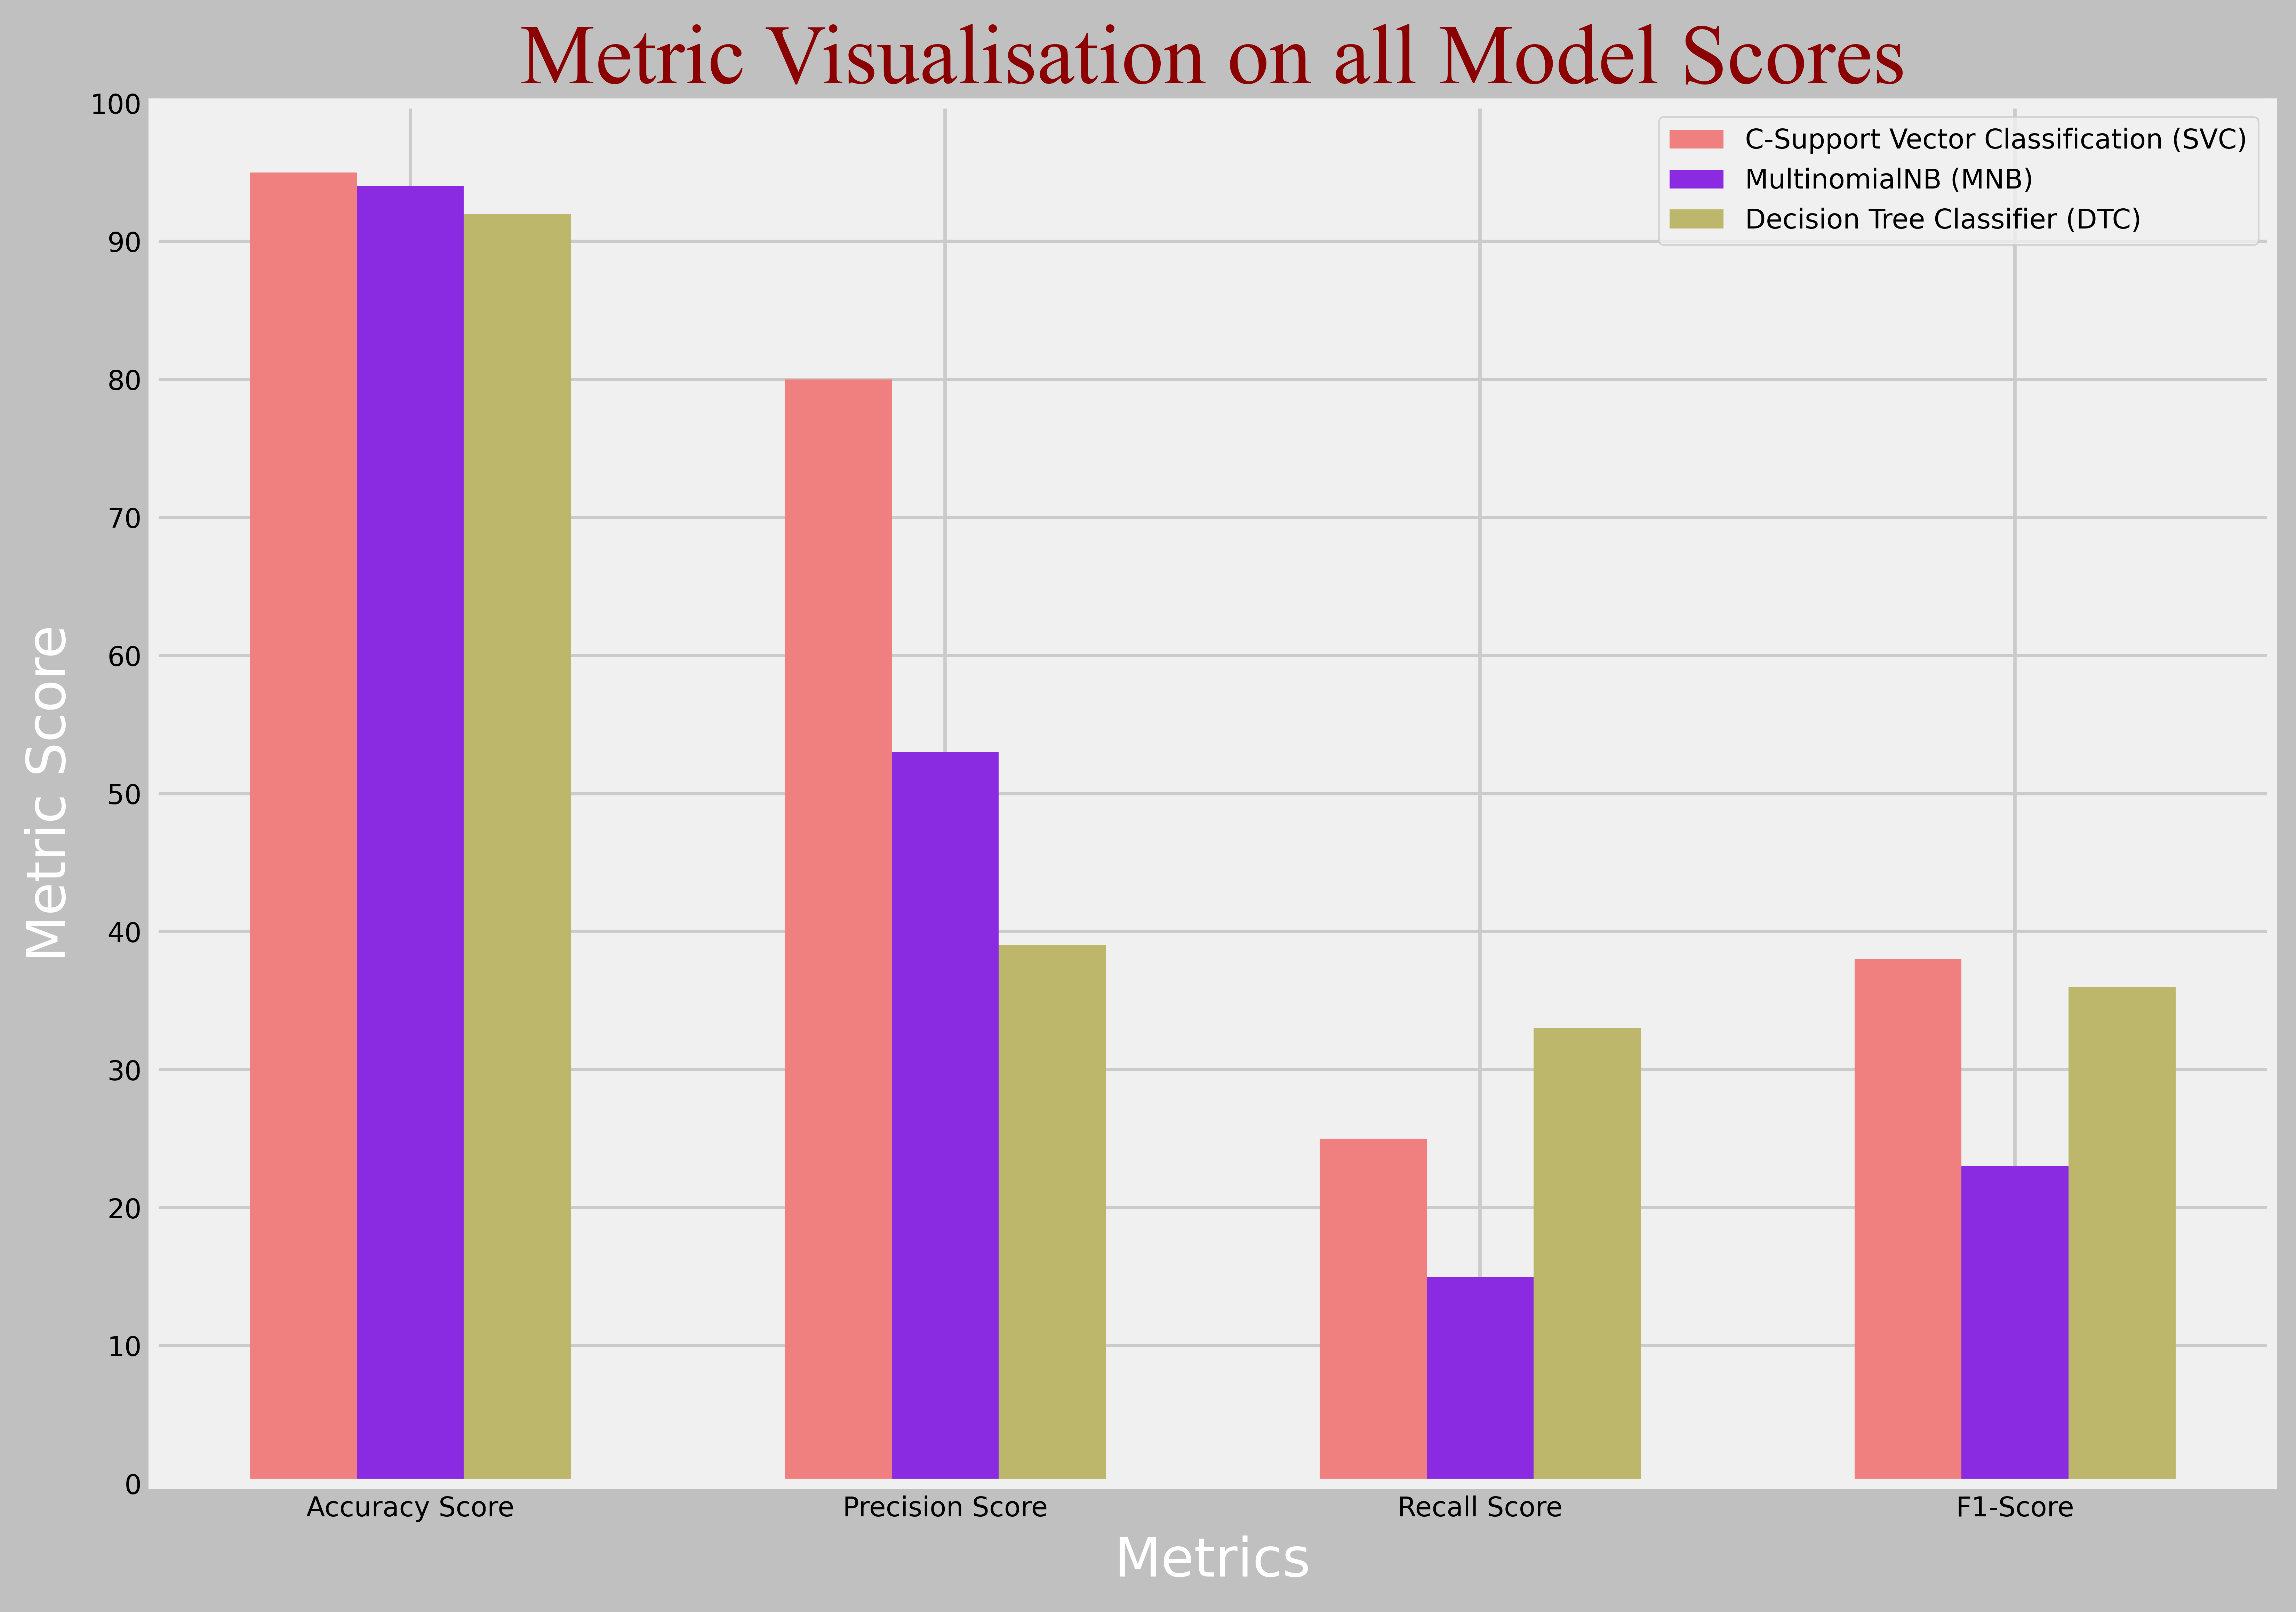

End of the Workshop 02.


In [24]:
svc_scores = (
    int(svc_accuracy_score * 100), 
    int(svc_precision_score * 100), 
    int(svc_recall_score * 100), 
    int(svc_f1_score * 100)
)
mnb_scores = (
    int(mnb_accuracy_score * 100), 
    int(mnb_precision_score * 100), 
    int(mnb_recall_score * 100), 
    int(mnb_f1_score * 100)
)
dtc_scores = (
    int(dtc_accuracy_score * 100), 
    int(dtc_precision_score * 100), 
    int(dtc_recall_score * 100), 
    int(dtc_f1_score * 100)
)
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 105, 10)]
xpos = np.arange(len(x_grid))
bar_width = .2

style.use("fivethirtyeight")
plt.rcParams['font.size'] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Metric Visualisation on all Model Scores", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, svc_scores, width=bar_width, color="lightcoral", label="C-Support Vector Classification (SVC)")
plt.bar((xpos + 0.2), mnb_scores, width=bar_width, color="blueviolet", label="MultinomialNB (MNB)")
plt.bar((xpos + 0.4), dtc_scores, width=bar_width, color="darkkhaki", label="Decision Tree Classifier (DTC)")
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.2), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.savefig("Workshop 2 - Graph.jpg", dpi=700)
plt.show()

print("End of the Workshop 02.")

<br>
<br>

## __<center><u>Assessment</u></center>__

In [25]:
formspring_df = pd.read_csv("Formspring.csv")

print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[:10]

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,No
1,Q: <3<br>A: </3 ? haha jk! <33,No
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,No
3,Q: (:<br>A: ;(,No
4,Q: ******************MEOWWW*******************...,No
5,Q: any makeup tips? i suck at doing my makeup ...,No
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,No
7,Q: Are you a morning or night person?<br>A: Ni...,No
8,Q: are you a trusting person?<br>A: alreadi an...,No
9,Q: are you a trusting person?<br>A: Yes veryy ...,No


In [26]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[-10:]

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
13137,Q: Your bio says &quot;Always ready for advent...,No
13138,Q: your going to mcdonalds what do you order ...,No
13139,Q: Your home alone. 2 robbers (of the opposite...,No
13140,Q: Your parents are divorced. One of them gets...,No
13141,Q: your thoughts on 2012? I think it&#039;ll b...,No
13142,Q: Youre at a party and your friend who drove ...,No
13143,Q: Youu2019re awesome :] Give yourself a compl...,No
13144,Q: Yu play with yurself ?<br>A: all the time. ...,No
13145,Q: yukk beer is disgusting. i can only drink i...,No
13146,Q: if i told u den it would make it all the le...,No


In [27]:
formspring_df.drop_duplicates(inplace=True)

formspring_df_rows = formspring_df.shape[0]
formspring_df_columns = formspring_df.shape[1]

print("The Dataset - Formspring.csv has {rows:,} rows "\
      "and {columns} columns.".format(rows=formspring_df_rows, columns=formspring_df_columns))

The Dataset - Formspring.csv has 13,144 rows and 2 columns.


In [28]:
formspring_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13144 entries, 0 to 13146
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    13144 non-null  object
 1   answer  13144 non-null  object
dtypes: object(2)
memory usage: 308.1+ KB


In [29]:
print("A generate descriptive statistics from the 'Dataset - Formspring.csv':")
print('-' * 73)
formspring_df.describe()

A generate descriptive statistics from the 'Dataset - Formspring.csv':
-------------------------------------------------------------------------


,text,answer
count,13144,13144
unique,13144,2
top,Q: if i told u den it would make it all the le...,No
freq,1,12292


In [30]:
print("Detecting missing values from the 'Dataset - Formspring.csv':")
print('-' * 63)
print(formspring_df.isnull().sum())

Detecting missing values from the 'Dataset - Formspring.csv':
---------------------------------------------------------------
text      0
answer    0
dtype: int64


In [31]:
# Creates a new "Instance - Lenght" and stores the sum of the length values from the "Column - text":
formspring_df["Length"] = formspring_df.text.apply(len)

# Encodes the "Column - answer" from the "Dataset - Formspring.csv" to boolean format:
formspring_df.answer = formspring_df.answer.map({
    "Yes": 1, 
    "No": 0
})

In [32]:
print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[:10]

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer,Length
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0,84
1,Q: <3<br>A: </3 ? haha jk! <33,0,30
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0,69
3,Q: (:<br>A: ;(,0,14
4,Q: ******************MEOWWW*******************...,0,66
5,Q: any makeup tips? i suck at doing my makeup ...,0,114
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0,120
7,Q: Are you a morning or night person?<br>A: Ni...,0,59
8,Q: are you a trusting person?<br>A: alreadi an...,0,50
9,Q: are you a trusting person?<br>A: Yes veryy ...,0,80


In [33]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[:10]

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer,Length
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0,84
1,Q: <3<br>A: </3 ? haha jk! <33,0,30
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0,69
3,Q: (:<br>A: ;(,0,14
4,Q: ******************MEOWWW*******************...,0,66
5,Q: any makeup tips? i suck at doing my makeup ...,0,114
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0,120
7,Q: Are you a morning or night person?<br>A: Ni...,0,59
8,Q: are you a trusting person?<br>A: alreadi an...,0,50
9,Q: are you a trusting person?<br>A: Yes veryy ...,0,80


<br>

## Data Pre-Processing

In [34]:
def preprocess(dataframe):
    messages = dataframe.translate(str.maketrans('', '', string.punctuation))
    messages = [word for word in messages.split() if word.lower() not in stopwords.words("english")]
    spam_words = ''
    
    print(messages)  # Un-comment to dislay texts...

    for message in messages:
        stemmer = SnowballStemmer("english")
        spam_words += (stemmer.stem(message)) + " "

    return spam_words


formspring_df_text_features = formspring_df["text"].copy()
formspring_df_text_features = formspring_df_text_features.apply(preprocess)
formspring_df_features = tfid_vectorizer.fit_transform(formspring_df_text_features)

LookupError: 
**********************************************************************
  Resource [93mstopwords[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('stopwords')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mcorpora/stopwords[0m

  Searched in:
    - 'C:\\Users\\enock/nltk_data'
    - 'C:\\Users\\enock\\anaconda3\\nltk_data'
    - 'C:\\Users\\enock\\anaconda3\\share\\nltk_data'
    - 'C:\\Users\\enock\\anaconda3\\lib\\nltk_data'
    - 'C:\\Users\\enock\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************


<br>

## Applying Vectorizer to Texts

In [ ]:
print("Text Features from the 'Pre-Processed Dataset - Formspring.csv':")
print('-' * 73)
print(formspring_df_text_features)

<br>

## Testing and Training Dataframe

In [ ]:
df_text_features = pd.DataFrame(formspring_df_text_features)

df_text_features.to_csv("My Formspring Features.csv")

df_features_train, df_features_test, df_labels_train, df_labels_test = train_test_split(
        formspring_df_features, formspring_df["answer"], test_size=0.3, random_state=4861
    )

In [ ]:
print("Dataframe Features Train:")
print('-' * 43)
print(df_features_train)

In [ ]:
print("Dataframe Features Test:")
print('-' * 53)
print(df_features_test)

In [ ]:
print("Dataframe Labels Train:")
print('-' * 27)
print(df_labels_train)

In [ ]:
print("Dataframe Labels Test:")
print('-' * 27)
print(df_labels_test)

<br>
<br>

## <center><u>Application of GridSearchCV on all Regression Models</u></center>

In [ ]:
# ------------------------------------------ GridSearchCV: Ridge ------------------------------------------- #
ridge_reg_model = Ridge()
ridge_param_grid = [
    {
        "fit_intercept": [False], 
        "max_iter": np.linspace(start=100, stop=1000, num=11, dtype=int), 
        # "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"], 
        "positive": [True]
    }
]

ridge_reg_clf = GridSearchCV(estimator=ridge_reg_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_reg_best_clf = ridge_reg_clf.fit(df_features_train, df_labels_train)
ridge_reg_best_model = ridge_reg_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 10secs -------------------------------- #

In [ ]:
# ----------------------------------- GridSearchCV: Logistic Regression ------------------------------------ #
lr_model = LogisticRegression()
lr_param_grid = [
    {
        "penalty": ["l1", "l2", "elasticnet"], 
        "dual": [True, False], 
        "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        # "C": np.logspace(start=-2, stop=3, num=7), 
        "fit_intercept": [True, False], 
        "solver": ["lbfgs", "liblinear", "newton-cg", "sag", "saga"], 
        "max_iter": np.linspace(start=100, stop=1000, num=10, dtype=int), 
        "multi_class": ["auto", "ovr", "multinomial"]
    }
]

lr_clf = GridSearchCV(estimator=lr_model, param_grid=lr_param_grid, cv=3, n_jobs=-1)
lr_best_clf = lr_clf.fit(df_features_train, df_labels_train)
lr_best_model = lr_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 5mins --------------------------------- #

In [ ]:
# ------------------------- GridSearchCV: Epsilon-Support Vector Regression - SVR -------------------------- #
svr_model = SVR()
svr_param_grid = [
    {
        "kernel": ["linear", "poly", "rbf", "sigmoid"], 
        # "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "C": np.logspace(start=-2, stop=3, num=7), 
        "shrinking": [True, False], 
        "max_iter": np.linspace(start=100, stop=3000, num=10, dtype=int)
    }
]

svr_clf = GridSearchCV(estimator=svr_model, param_grid=svr_param_grid, cv=3,n_jobs=-1)
svr_best_clf = svr_clf.fit(df_features_train, df_labels_train)
svr_best_model = svr_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 15mins -------------------------------- #

In [ ]:
# -------------------------- GridSearchCV: Stochastic Gradient Descent Regressor --------------------------- #
sgd_reg_model = SGDRegressor()
sgd_reg_param_grid = [
    {
        "loss": ["squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"], 
        "penalty": ["l2", "l1", "elasticnet"], 
        "alpha": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "fit_intercept": [True, False], 
        "max_iter": np.linspace(start=1000, stop=3000, num=5, dtype=int), 
        "shuffle": [True, False], 
        "learning_rate": ["constant", "optimal", "invscaling", "adaptive"], 
        "average": [True, False]
    }
]

sgd_reg_clf = GridSearchCV(estimator=sgd_reg_model, param_grid=sgd_reg_param_grid, cv=3, n_jobs=-1)
sgd_reg_best_clf = sgd_reg_clf.fit(df_features_train, df_labels_train)
sgd_reg_best_model = sgd_reg_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 15mins -------------------------------- #

<br>

## <center><u>Implementing Regression Models</u></center>

In [ ]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
regression_best_models = [  # Regression models below...
    ridge_reg_best_model, lr_best_model, svr_best_model, sgd_reg_best_model
]

for i, model in enumerate(regression_best_models):
    print(f"|Model {(i + 1)}|: {model}")

In [ ]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Regression": Ridge(fit_intercept=False, max_iter=100, positive=True), 
    "Logistic Regression": LogisticRegression(max_iter=700, penalty="l1", solver="saga", tol=0.070030), 
    "Epsilon-Support Vector Regression": SVR(C=0.464159, kernel="sigmoid", max_iter=2033, shrinking=False), 
    "Stochastic Gradient Descent Regressor": SGDRegressor(learning_rate="adaptive", max_iter=3000)
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(df_features_train, df_labels_train)

    model_prediction = model.predict(df_features_test)
    model_accuracy_score = accuracy_score(df_labels_test, model_prediction.round())
    model_precision_score = precision_score(df_labels_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(df_labels_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(df_labels_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(97, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              df_labels_test, model_prediction.round())
          ) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              df_labels_test, model_prediction.round())
          ) + "\n" + 
          "THE END".center(97, '-'))
# ---------------------------------------------------------------------------------------------------------- #

<br>

## <center><u>Visualising the Metric Scores for all Regression Models</u></center>

In [ ]:
ridge_reg_scores = (
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
)
lr_scores = (
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
)
svr_scores = (
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
)
sgd_reg_scores = (
    model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3], 
)
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .18

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Metric Visualisation on all Regression Models", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_reg_scores, width=bar_width, color="darkorange", label="Ridge Regression")
plt.bar((xpos + 0.18), lr_scores, width=bar_width, color="forestgreen", label="Logistic Regression")
plt.bar(
    (xpos + 0.36), svr_scores, width=bar_width, color="lightcoral", 
    label="Epsilon-Support Vector Regression (SVR)"
)
plt.bar(
    (xpos + 0.54), sgd_reg_scores, width=bar_width, color="indigo", 
    label="Stochastic Gradient Descent Regressor - SGD"
)
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()

<br>
<br>

## <center><u>Application of GridSearchCV on all Classifier Models</u></center>

In [ ]:
# ------------------------------------- GridSearchCV: Ridge Classifier ------------------------------------- #
ridge_model = RidgeClassifier()
ridge_param_grid = [
    {
        "fit_intercept": [False], 
        "max_iter": np.linspace(start=100, stop=1000, num=11, dtype=int), 
        "tol": np.logspace(start=-3, stop=-2, num=11), 
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"], 
        "positive": [True]
    }
]

ridge_clf = GridSearchCV(estimator=ridge_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_best_clf = ridge_clf.fit(df_features_train, df_labels_train)
ridge_best_model = ridge_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 1mins --------------------------------- #

In [ ]:
# ------------------------------ GridSearchCV: Multinomial Naive Bayes (MNB) ------------------------------- #
mnb_model = MultinomialNB()
mnb_param_grid = [
    {
        "alpha": np.logspace(start=0, stop=2, num=30), 
        "force_alpha": [True, False], 
        "fit_prior": [True, False]
    }
]

mnb_clf = GridSearchCV(estimator=mnb_model, param_grid=mnb_param_grid, cv=3, n_jobs=-1)
mnb_best_clf = mnb_clf.fit(df_features_train, df_labels_train)
mnb_best_model = mnb_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 5secs --------------------------------- #

In [ ]:
# -------------------------- GridSearchCV: C-Support Vector Classification (SVC) --------------------------- #
svc_model = SVC()
svc_param_grid = [
    {
        "C": np.logspace(start=-2, stop=3, num=7), 
        "kernel": ["linear", "poly", "rbf", "sigmoid"], 
        # "shrinking": [True, False], 
        # "probability": [True, False], 
        # "tol": np.logspace(start=-3, stop=-2, num=11), 
        "max_iter": np.linspace(start=1000, stop=3000, num=11, dtype=int), 
        "decision_function_shape": ["ovo", "ovr"]
        # "break_ties": [True, False]
    }
]

svc_clf = GridSearchCV(estimator=svc_model, param_grid=svc_param_grid, cv=3, n_jobs=-1)
svc_clf_best = svc_clf.fit(df_features_train, df_labels_train)
svc_best_model = svc_clf_best.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 15mins -------------------------------- #

In [ ]:
# ----------------------- GridSearchCV: Stochastic Gradient Descent Classifier (SGD) ----------------------- #
sgd_model = SGDClassifier()
sgd_param_grid = [
    {
        "loss": ["hinge", "log_loss", "log", "modified_huber", "squared_hinge", "perceptron", 
                 "squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"], 
        "penalty": ["l2", "l1", "elasticnet"], 
        # "alpha": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "fit_intercept": [True, False], 
        "max_iter": np.linspace(start=1000, stop=3000, num=5, dtype=int), 
        "shuffle": [True, False], 
        "learning_rate": ["constant", "optimal", "invscaling", "adaptive"], 
        "early_stopping": [True, False], 
        # "warm_start": [True, False], 
        "average": [True, False]
    }
]

sgd_clf = GridSearchCV(estimator=sgd_model, param_grid=sgd_param_grid, cv=3, n_jobs=-1)
sgd_best_clf = sgd_clf.fit(df_features_train, df_labels_train)
sgd_best_model = sgd_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 10mins -------------------------------- #

<br>

## <center><u>Implementing Classifier Models</u></center>

In [ ]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
classifier_best_models = [  # Regression models below...
    ridge_best_model, mnb_best_model, svc_best_model, sgd_best_model
]

for i, model in enumerate(classifier_best_models):
    print(f"|Model {(i + 1)}|: {model}")

In [ ]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Classifier": Ridge(fit_intercept=False, max_iter=100, positive=True, tol=0.001), 
    "Multinomial Naive Bayes": MultinomialNB(force_alpha=True), 
    "C-Support Vector Classification": SVC(C=21.544347, decision_function_shape="ovo", max_iter=1000), 
    "Stochastic Gradient Descent Classifier": SGDClassifier(max_iter=3000, penalty="elasticnet")
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(df_features_train, df_labels_train)

    model_prediction = model.predict(df_features_test)
    model_accuracy_score = accuracy_score(df_labels_test, model_prediction.round())
    model_precision_score = precision_score(df_labels_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(df_labels_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(df_labels_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(90, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              df_labels_test, model_prediction.round())
          ) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              df_labels_test, model_prediction.round())
          ) + "\n" + 
          "THE END".center(90, '-'))
# ---------------------------------------------------------------------------------------------------------- #

<br>

## <center><u>Visualising the Metric Scores for all Classifier Models</u></center>

In [ ]:
ridge_scores = [
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
]
mnb_scores = [
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
]
svc_scores = [
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
]
sgd_scores = [
    model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3], 
]
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .18

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Visualising Classifier Model Scores", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_scores, width=bar_width, color="darkorange", label="Ridge Classifier")
plt.bar(
    (xpos + 0.18), mnb_scores, width=bar_width, color="forestgreen", label="Multinomial Naive Bayes (MNB)"
)
plt.bar(
    (xpos + 0.36), svc_scores, width=bar_width, color="deepskyblue", 
    label="C-Support Vector Classification (SVC)"
)
plt.bar(
    (xpos + 0.54), sgd_scores, width=bar_width, color="lightcoral", 
    label="Stochastic Gradient Descent Classifier (SGD)"
)
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()

<br>

## <center><u>Training with Additional Dataset</u></center>

In [ ]:
cyber_bullying_df = pd.read_csv("Cyber-Bullying.csv")

print("First 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 85)
cyber_bullying_df.head(10)

In [ ]:
print("Last 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 85)
cyber_bullying_df.tail(10)

In [ ]:
# Dropping the "Columns: index and Date", since they are not required:
cyber_bullying_df.drop(["index", "Date"], axis=1, inplace=True)

print("First 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 63)
cyber_bullying_df.head(10)

In [ ]:
print("Last 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 63)
cyber_bullying_df.tail(10)

In [ ]:
# Renaming the "Column: oh_label" to "Column: answer" and the "Column: Text" to the "Column: text":
cyber_bullying_df.rename(columns={"oh_label": "answer", "Text": "text"}, inplace=True)

cyber_bullying_df = cyber_bullying_df[["text", "answer"]]  # Repostioning the Columns...
cyber_bullying_df["Length"] = cyber_bullying_df.text.apply(len)

print("First 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 63)
cyber_bullying_df.head(10)

In [ ]:
print("Last 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 63)
cyber_bullying_df.tail(10)

In [ ]:
# Combined "Datasets: Cyber-Bullying.csv and Formspring.csv" into one dataset:
new_df = pd.concat([cyber_bullying_df, formspring_df], axis=0)

# Stored the combined datasets into a "File: Datasets-Combined.csv":
new_df.to_csv("Datasets-Combined.csv", index=False)

new_df.answer = new_df.answer.replace(1, "Yes")
new_df.answer = new_df.answer.replace(0, "No")

In [ ]:
print("First 10 Elements from the 'Dataset - Datasets-Combined.csv':")
print('-' * 63)
new_df.head(10)

In [ ]:
print("Last 10 Elements from the 'Dataset - Datasets-Combined.csv':")
print('-' * 63)
new_df.tail(10)

In [ ]:
print(f"The 'Dataset - Datasets-Combined.csv' has {new_df.shape[0]:,} rows and {new_df.shape[1]} columns.")

In [ ]:
new_df.drop_duplicates(inplace=True)

print(f"After removing duplcates, the 'Dataset - Datasets-Combined.csv' now has {new_df.shape[0]:,} rows and \
{new_df.shape[1]} columns.")

In [ ]:
new_df.info()

In [ ]:
new_df.describe().T

In [ ]:
new_df.isnull().sum()

In [ ]:
text_features = new_df.text.copy()
text_features = text_features.apply(preprocess)
new_df_features = tfid_vectorizer.fit_transform(text_features)

In [ ]:
print("Text Features from the 'Pre-Processed Dataset - Datasets-Combined.csv':")
print('-' * 74)
print(text_features)

In [ ]:
# Get specific column name:
column = ["answer"]

print("Column:", column)

In [ ]:
for i in column:
    # print(i)

    new_df[i] = label_encoder.fit_transform(new_df[i])

print("Formspring Dataset Data Types:")
print('-' * 33)
print(new_df.dtypes)

In [ ]:
print("First 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 69)
new_df.head(10)

In [ ]:
print("Last 10 Elements from the 'Dataset - Cyber-Bullying.csv':")
print('-' * 69)
new_df.tail(10)

<br>

## Testing and Training Dataframe

In [ ]:
new_df_text_features = pd.DataFrame(text_features)

new_df_text_features.to_csv("My Features (Combined Dataset).csv")

X_train, X_test, y_train, y_test = train_test_split(
    new_df_features, new_df["answer"], test_size=0.3, random_state=4861
)

In [ ]:
print("Dataframe Features Train:")
print('-' * 43)
print(X_train)

In [ ]:
print("Dataframe Features Test:")
print('-' * 53)
print(X_test)

In [ ]:
print("Dataframe Labels Train:")
print('-' * 27)
print(y_train)

In [ ]:
print("Dataframe Labels Test:")
print('-' * 27)
print(y_test)

<br>
<br>

## <center><u>Application of GridSearchCV on all Regression Models</u></center>

In [ ]:
# ------------------------------------------ GridSearchCV: Ridge ------------------------------------------- #
ridge_reg_model = Ridge()
ridge_param_grid = [
    {
        "fit_intercept": [False], 
        "max_iter": np.linspace(start=100, stop=1000, num=11, dtype=int), 
        # "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"], 
        "positive": [True]
    }
]

ridge_reg_clf = GridSearchCV(estimator=ridge_reg_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_reg_best_clf = ridge_reg_clf.fit(X_train, y_train)
ridge_reg_best_model = ridge_reg_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 10secs -------------------------------- #

In [ ]:
# ----------------------------------- GridSearchCV: Logistic Regression ------------------------------------ #
lr_model = LogisticRegression()
lr_param_grid = [
    {
        "penalty": ["l1", "l2", "elasticnet"], 
        "dual": [True, False], 
        "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        # "C": np.logspace(start=-2, stop=3, num=7), 
        "fit_intercept": [True, False], 
        "solver": ["lbfgs", "liblinear", "newton-cg", "sag", "saga"], 
        "max_iter": np.linspace(start=100, stop=1000, num=10, dtype=int), 
        "multi_class": ["auto", "ovr", "multinomial"]
    }
]

lr_clf = GridSearchCV(estimator=lr_model, param_grid=lr_param_grid, cv=3, n_jobs=-1)
lr_best_clf = lr_clf.fit(X_train, y_train)
lr_best_model = lr_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 15mins -------------------------------- #

In [ ]:
# ------------------------- GridSearchCV: Epsilon-Support Vector Regression - SVR -------------------------- #
svr_model = SVR()
svr_param_grid = [
    {
        "kernel": ["linear", "poly", "rbf", "sigmoid"], 
        # "tol": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "C": np.logspace(start=-2, stop=3, num=7), 
        "shrinking": [True, False], 
        "max_iter": np.linspace(start=100, stop=3000, num=10, dtype=int)
    }
]

svr_clf = GridSearchCV(estimator=svr_model, param_grid=svr_param_grid, cv=3,n_jobs=-1)
svr_best_clf = svr_clf.fit(X_train, y_train)
svr_best_model = svr_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 30mins -------------------------------- #

In [ ]:
# -------------------------- GridSearchCV: Stochastic Gradient Descent Regressor --------------------------- #
sgd_reg_model = SGDRegressor()
sgd_reg_param_grid = [
    {
        "loss": ["squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"], 
        "penalty": ["l2", "l1", "elasticnet"], 
        "alpha": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "fit_intercept": [True, False], 
        "max_iter": np.linspace(start=1000, stop=3000, num=5, dtype=int), 
        "shuffle": [True, False], 
        "learning_rate": ["constant", "optimal", "invscaling", "adaptive"], 
        "average": [True, False]
    }
]

sgd_reg_clf = GridSearchCV(estimator=sgd_reg_model, param_grid=sgd_reg_param_grid, cv=3, n_jobs=-1)
sgd_reg_best_clf = sgd_reg_clf.fit(X_train, y_train)
sgd_reg_best_model = sgd_reg_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 25mins -------------------------------- #

<br>

## <center><u>Implementing Regression Models</u></center>

In [ ]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
regression_best_models = [  # Regression models below...
    ridge_reg_best_model, lr_best_model, svr_best_model, sgd_reg_best_model
]

for i, model in enumerate(regression_best_models):
    print(f"|Model {(i + 1)}|: {model}")

In [ ]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Regression": Ridge(fit_intercept=False, max_iter=100, positive=True), 
    "Logistic Regression": LogisticRegression(max_iter=600, penalty="l1", solver="saga", tol=0.080020), 
    "Epsilon-Support Vector Regression": SVR(C=0.464159, kernel="linear", max_iter=3000), 
    "Stochastic Gradient Descent Regressor": SGDRegressor(learning_rate="adaptive", max_iter=2000)
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(X_train, y_train)

    model_prediction = model.predict(X_test)
    model_accuracy_score = accuracy_score(y_test, model_prediction.round())
    model_precision_score = precision_score(y_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(y_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(y_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(97, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              y_test, model_prediction.round())) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              y_test, model_prediction.round())) + "\n" + 
          "THE END".center(97, '-'))
# ---------------------------------------------------------------------------------------------------------- #

<br>

## <center><u>Visualising the Metric Scores for all Regression Models</u></center>

In [ ]:
ridge_reg_scores = (
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
)
lr_scores = (
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
)
svr_scores = (
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
)
sgd_reg_scores = (
    model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3], 
)
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .18

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Metric Visualisation on all Regression Models", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_reg_scores, width=bar_width, color="darkorange", label="Ridge Regression")
plt.bar((xpos + 0.18), lr_scores, width=bar_width, color="forestgreen", label="Logistic Regression")
plt.bar(
    (xpos + 0.36), svr_scores, width=bar_width, color="lightcoral", 
    label="Epsilon-Support Vector Regression (SVR)"
)
plt.bar(
    (xpos + 0.54), sgd_reg_scores, width=bar_width, color="indigo", 
    label="Stochastic Gradient Descent Regressor - SGD"
)
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()

<br>
<br>

## <center><u>Application of GridSearchCV on all Classifier Models</u></center>

In [ ]:
# ------------------------------------- GridSearchCV: Ridge Classifier ------------------------------------- #
ridge_model = RidgeClassifier()
ridge_param_grid = [
    {
        "fit_intercept": [False], 
        "max_iter": np.linspace(start=100, stop=1000, num=11, dtype=int), 
        "tol": np.logspace(start=-3, stop=-2, num=11), 
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"], 
        "positive": [True]
    }
]

ridge_clf = GridSearchCV(estimator=ridge_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_best_clf = ridge_clf.fit(X_train, y_train)
ridge_best_model = ridge_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 1mins --------------------------------- #

In [ ]:
# ------------------------------ GridSearchCV: Multinomial Naive Bayes (MNB) ------------------------------- #
mnb_model = MultinomialNB()
mnb_param_grid = [
    {
        "alpha": np.logspace(start=0, stop=2, num=30), 
        "force_alpha": [True, False], 
        "fit_prior": [True, False]
    }
]

mnb_clf = GridSearchCV(estimator=mnb_model, param_grid=mnb_param_grid, cv=3, n_jobs=-1)
mnb_best_clf = mnb_clf.fit(X_train, y_train)
mnb_best_model = mnb_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 5secs --------------------------------- #

In [ ]:
# -------------------------- GridSearchCV: C-Support Vector Classification (SVC) --------------------------- #
svc_model = SVC()
svc_param_grid = [
    {
        "C": np.logspace(start=-2, stop=3, num=7), 
        "kernel": ["linear", "poly", "rbf", "sigmoid"], 
        # "shrinking": [True, False], 
        # "probability": [True, False], 
        # "tol": np.logspace(start=-3, stop=-2, num=11), 
        "max_iter": np.linspace(start=1000, stop=3000, num=11, dtype=int), 
        "decision_function_shape": ["ovo", "ovr"]
        # "break_ties": [True, False]
    }
]

svc_clf = GridSearchCV(estimator=svc_model, param_grid=svc_param_grid, cv=3, n_jobs=-1)
svc_clf_best = svc_clf.fit(X_train, y_train)
svc_best_model = svc_clf_best.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 35mins -------------------------------- #

In [ ]:
# ----------------------- GridSearchCV: Stochastic Gradient Descent Classifier (SGD) ----------------------- #
sgd_model = SGDClassifier()
sgd_param_grid = [
    {
        "loss": ["hinge", "log_loss", "log", "modified_huber", "squared_hinge", "perceptron", 
                 "squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"], 
        "penalty": ["l2", "l1", "elasticnet"], 
        # "alpha": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        "fit_intercept": [True, False], 
        "max_iter": np.linspace(start=1000, stop=3000, num=5, dtype=int), 
        "shuffle": [True, False], 
        "learning_rate": ["constant", "optimal", "invscaling", "adaptive"], 
        "early_stopping": [True, False], 
        # "warm_start": [True, False], 
        "average": [True, False]
    }
]

sgd_clf = GridSearchCV(estimator=sgd_model, param_grid=sgd_param_grid, cv=3, n_jobs=-1)
sgd_best_clf = sgd_clf.fit(X_train, y_train)
sgd_best_model = sgd_best_clf.best_estimator_
# -------------------------------- Estimated Parameter Search Time ≈ 10mins -------------------------------- #

<br>

## <center><u>Implementing Classifier Models</u></center>

In [ ]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
classifier_best_models = [  # Regression models below...
    ridge_best_model, mnb_best_model, svc_best_model, sgd_best_model
]

for i, model in enumerate(classifier_best_models):
    print(f"|Model {(i + 1)}|: {model}")

In [ ]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Classifier": Ridge(fit_intercept=False, max_iter=100, positive=True, tol=0.001), 
    "Multinomial Naive Bayes": MultinomialNB(alpha=3.039195, fit_prior=False, force_alpha=True), 
    "C-Support Vector Classification": SVC(C=21.544347, decision_function_shape="ovo", max_iter=2000), 
    "Stochastic Gradient Descent Classifier": SGDClassifier(average=True, max_iter=3000)
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(X_train, y_train)

    model_prediction = model.predict(X_test)
    model_accuracy_score = accuracy_score(y_test, model_prediction.round())
    model_precision_score = precision_score(y_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(y_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(y_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(90, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              y_test, model_prediction.round())) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              y_test, model_prediction.round())) + "\n" + 
          "THE END".center(90, '-'))
# ---------------------------------------------------------------------------------------------------------- #

<br>

## <center><u>Visualising the Metric Scores for all Classifier Models</u></center>

In [ ]:
ridge_scores = [
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
]
mnb_scores = [
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
]
svc_scores = [
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
]
sgd_scores = [
    model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3], 
]
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .1

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Visualising Classifier Model Scores", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_scores, width=bar_width, color="darkorange", label="Ridge Classifier")
plt.bar(
    (xpos + 0.18), mnb_scores, width=bar_width, color="forestgreen", label="Multinomial Naive Bayes (MNB)"
)
plt.bar(
    (xpos + 0.36), svc_scores, width=bar_width, color="deepskyblue", 
    label="C-Support Vector Classification (SVC)"
)
plt.bar(
    (xpos + 0.54), sgd_scores, width=bar_width, color="lightcoral", 
    label="Stochastic Gradient Descent Classifier (SGD)"
)
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()



#### ___<center><u>Output for the Evaluation Metrics with all Regression Models</u></center>___

|                 Models                  |         Metric Scores         |
|:---------------------------------------:|:-----------------------------:|
| ___Logistic Regression___               | _Accuracy Score: 98.205742%_  |
|                                         | _Precision Score: 98.189846%_ |
|                                         | _Recall Score: 98.205742%_    |
|                                         | _F1-Score: 98.178658%_        |
| ___Ridge___                             | _Accuracy Score: 97.787081%_  |
|                                         | _Precision Score: 97.871260%_ |
|                                         | _Recall Score: 97.787081%_    |
|                                         | _F1-Score: 97.744099%_        |
| ___Epsilon-Support Vector Regression___ | _Accuracy Score: 98.026316%_  |
|                                         | _Precision Score: 98.093254%_ |
|                                         | _Recall Score: 98.026316%_    |
|                                         | _F1-Score: 98.003810%_        |

<br>
<br>

#### ___<center><u>Output for the Evaluation Metrics with all Classifier Models</u></center>___

|                 Models                  |         Metric Scores         |
|:---------------------------------------:|:-----------------------------:|
| ___C-Support Vector Classifier___       | _Accuracy Score: 98.086124%_  |
|                                         | _Precision Score: 98.066456%_ |
|                                         | _Recall Score: 98.086124%_    |
|                                         | _F1-Score: 98.057235%_        |
| ___Decision Tree Classifier___          | _Accuracy Score: 97.009569%_  |
|                                         | _Precision Score: 96.962909%_ |
|                                         | _Recall Score: 97.009569%_    |
|                                         | _F1-Score: 96.976078%_        |
| ___Random Forest Classifier___          | _Accuracy Score: 97.428230%_  |
|                                         | _Precision Score: 97.502799%_ |
|                                         | _Recall Score: 97.428230%_    |
|                                         | _F1-Score: 97.315809%_        |


___Conclusion:___  


<br>
